# Notebook 01 — Module A: Revenue & Demand Forecasting

**Dataset:** UCI Online Retail II (cleaned in notebook 00).

**Objective:** forecast next week's **total net revenue** (sales minus cancellations, in £) using only information
available at the end of the previous week.

**Candidates** — all evaluated on the **same held-out weeks**:

| Group | Model | Role |
|---|---|---|
| Baselines | Naive (last week) | simplest forecast |
| | Training mean | "revenue stays at its usual level" |
| | **Seasonal naive** (same week last year) | the fair baseline for seasonal data |
| Weekly ML models | Linear Regression, Random Forest, XGBoost | one training row per week (~80 rows) |
| Daily ML models | Random Forest, **XGBoost** | one training row per *day*, predictions summed into weekly totals |
| Combination | average of seasonal naive and daily XGBoost | combines "what happened last year" with recent-trend learning |

Why the daily models? With only two years of data there are ~80 training weeks, which is very little for tree
models. Modelling **days** gives ~7× more training rows and lets the model learn day-of-week effects (e.g. no trading
on Saturdays), while the target we report is still **weekly** revenue.

## Setup

In [1]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from xgboost import XGBRegressor

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from forecast_features import DAILY_FEATURES, WEEKLY_FEATURES, daily_features, weekly_features

CLEAN_PATH = PROJECT_ROOT / "data" / "processed" / "online_retail_clean.csv.gz"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
PRED_DIR = PROJECT_ROOT / "outputs" / "predictions"
MODEL_DIR = PROJECT_ROOT / "models"
for folder in (FIG_DIR, TABLE_DIR, PRED_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titlesize": 13, "axes.labelsize": 11})
MAIN_COLOR = "#4C72B0"
ACCENT_COLOR = "#DD8452"

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"01_{name}.png", dpi=120, bbox_inches="tight")

retail = pd.read_csv(CLEAN_PATH, parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
print("Loaded cleaned lines:", retail.shape, "| run notebook 00 first if this file is missing")

Loaded cleaned lines: (1021272, 10) | run notebook 00 first if this file is missing


## Step 1 — Define the target: weekly net revenue

- Sum line `revenue` per calendar day (days with no trading become 0), then per week (Monday–Sunday, labelled by the Sunday).
- **Net revenue** includes cancellations as negative values (notebook 00 showed that this removes huge orders that were
  cancelled the same day).
- The data starts on Tuesday 1 Dec 2009 and ends on Friday 9 Dec 2011, so the **first and last weeks are incomplete
  and are dropped**.

In [2]:
daily_revenue = retail.set_index("InvoiceDate")["revenue"].resample("D").sum()
weekly_all = daily_revenue.resample("W-SUN").sum()
days_observed = retail.set_index("InvoiceDate")["revenue"].resample("W-SUN").apply(lambda s: s.index.normalize().nunique())

first_complete, last_complete = weekly_all.index[1], weekly_all.index[-2]
weekly_revenue = weekly_all.loc[first_complete:last_complete]
daily_revenue = daily_revenue.loc[first_complete - pd.Timedelta(days=6):last_complete]  # same complete weeks
print(f"First week ({weekly_all.index[0].date()}) and last week ({weekly_all.index[-1].date()}) dropped as incomplete.")
print(f"Complete weeks: {len(weekly_revenue)} ({weekly_revenue.index.min().date()} to {weekly_revenue.index.max().date()})")
weekly_revenue.describe().round(0)

First week (2009-12-06) and last week (2011-12-11) dropped as incomplete.
Complete weeks: 104 (2009-12-13 to 2011-12-04)


count       104.0
mean     176558.0
std       71176.0
min           0.0
25%      135848.0
50%      158922.0
75%      202832.0
max      369129.0
Name: revenue, dtype: float64

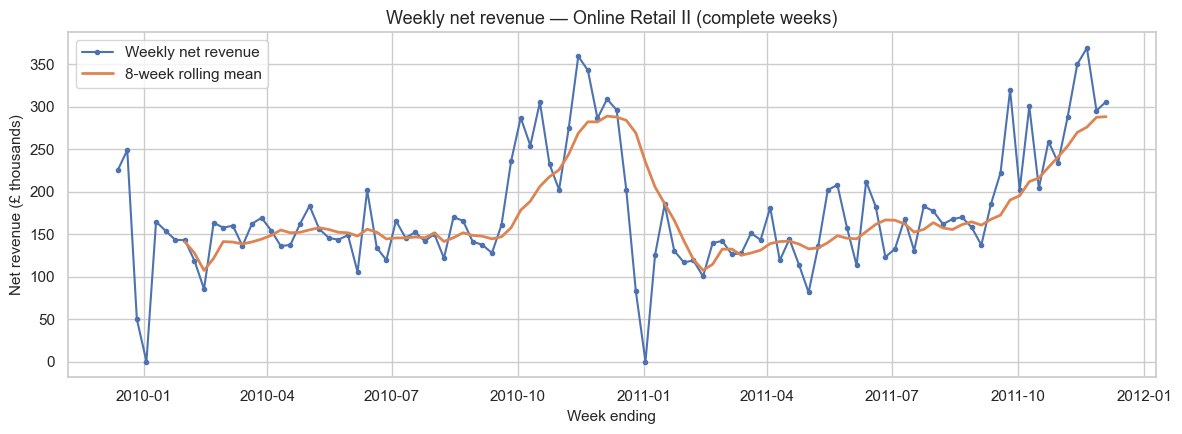

In [3]:
fig, ax = plt.subplots()
ax.plot(weekly_revenue.index, weekly_revenue / 1e3, marker="o", markersize=3, color=MAIN_COLOR, label="Weekly net revenue")
ax.plot(weekly_revenue.index, weekly_revenue.rolling(8).mean() / 1e3, color=ACCENT_COLOR, linewidth=2, label="8-week rolling mean")
ax.set_title("Weekly net revenue — Online Retail II (complete weeks)")
ax.set_xlabel("Week ending")
ax.set_ylabel("Net revenue (£ thousands)")
ax.legend()
save_fig("weekly_revenue")
plt.show()

**Interpretation:** a typical (median) week brings in about £159k, but revenue roughly **doubles every autumn**, peaking in
November at around £350–370k, then collapses to zero in the Christmas closure week. The rolling mean shows the same
shape in 2010 and 2011, with 2011 slightly higher.

## Step 2 — Is there predictable structure?

**Seasonality check:** overlay the two years by week of the year. **Autocorrelation:** is this week related to recent
weeks? A Ljung–Box p-value below 0.05 means the autocorrelation is stronger than random noise would produce.

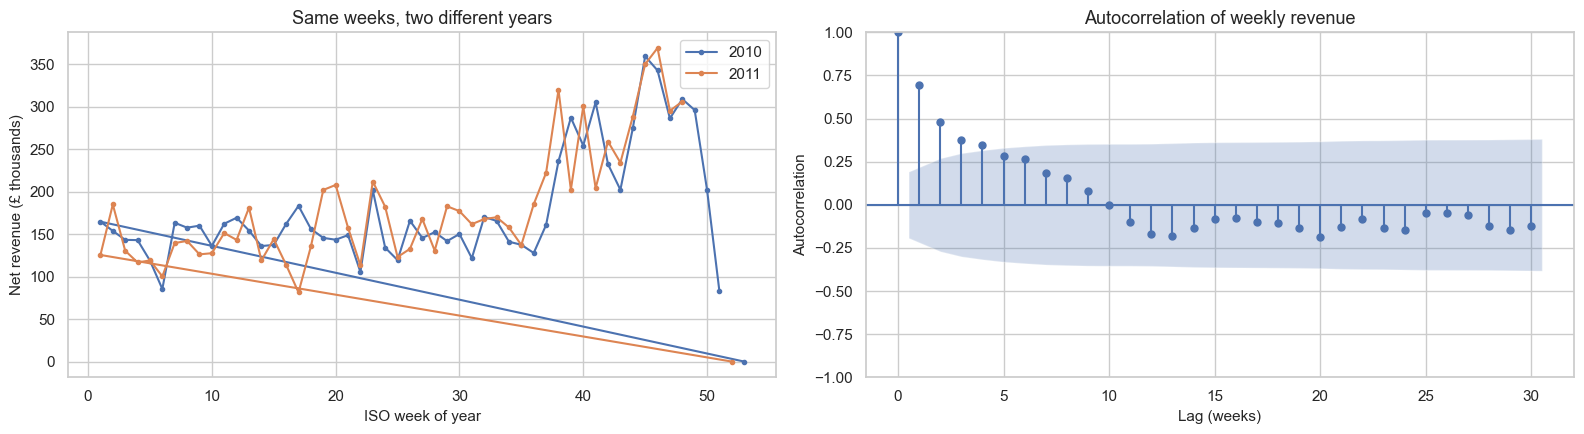

,lb_stat,lb_pvalue
lags_tested,,
4,105.4048,0.0
8,128.7431,0.0
12,134.2317,0.0


In [4]:
by_year = weekly_revenue.to_frame("revenue").assign(year=weekly_revenue.index.year,
                                                   week_of_year=weekly_revenue.index.isocalendar().week.values)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for year, color in [(2010, MAIN_COLOR), (2011, ACCENT_COLOR)]:
    subset = by_year[by_year["year"] == year]
    axes[0].plot(subset["week_of_year"], subset["revenue"] / 1e3, marker="o", markersize=3, color=color, label=str(year))
axes[0].set_title("Same weeks, two different years")
axes[0].set_xlabel("ISO week of year")
axes[0].set_ylabel("Net revenue (£ thousands)")
axes[0].legend()
plot_acf(weekly_revenue, lags=30, ax=axes[1], color=MAIN_COLOR)
axes[1].set_title("Autocorrelation of weekly revenue")
axes[1].set_xlabel("Lag (weeks)")
axes[1].set_ylabel("Autocorrelation")
save_fig("seasonality_autocorrelation")
plt.show()

ljung_box = acorr_ljungbox(weekly_revenue, lags=[4, 8, 12])
ljung_box.index.name = "lags_tested"
ljung_box.round(4)

**Interpretation:** the 2010 and 2011 curves follow almost the same path — flat in the first half of the year, a
steep rise from around week 36 (September) and a peak around week 45–47 (November). Last week's revenue is strongly
correlated with this week's (lag-1 autocorrelation ≈ 0.7), and the Ljung–Box p-values are essentially zero.

**Decision:** past revenue and the calendar position both carry real signal. The **seasonal-naive** forecast (same week
last year) is therefore a strong baseline that every ML model must beat to be worth using.

## Step 3 — Features (no leakage)

Feature builders live in `src/forecast_features.py` so that notebook 04 can reuse exactly the same logic.

**Weekly models** (one row per week): `lag_1`, `lag_2`, `lag_4` (revenue 1/2/4 weeks earlier), `rolling_mean_4`
(mean of the previous 4 weeks), `month`, `week_of_year`, `holiday_week` (22 Dec – 4 Jan).

**Daily models** (one row per day; predictions are summed into weekly totals): `prev_week`, `prev2_week`,
`rolling_mean_4_weeks` (totals of the previous weeks), `same_weekday_last_week`, `day_of_week`, `month`, `day_of_year`,
`holiday_period`. Every daily feature is known **at the end of the previous Sunday**, so the whole next week can be
forecast at once.

In [5]:
weekly_table = weekly_features(weekly_revenue)
daily_table = daily_features(daily_revenue)
print("Weekly feature table:", weekly_table.shape, "| daily feature table:", daily_table.shape)
daily_table.dropna().head(8)

Weekly feature table: (104, 9) | daily feature table: (728, 10)


,revenue,week_ending,prev_week,prev2_week,rolling_mean_4_weeks,same_weekday_last_week,day_of_week,month,day_of_year,holiday_period
InvoiceDate,,,,,,,,,,
2010-01-04,13170.15,2010-01-10,0.00,49825.01,130970.2175,0.00,0,1,4,1
2010-01-05,19017.39,2010-01-10,0.00,49825.01,130970.2175,0.00,1,1,5,0
2010-01-06,8733.00,2010-01-10,0.00,49825.01,130970.2175,0.00,2,1,6,0
2010-01-07,72250.13,2010-01-10,0.00,49825.01,130970.2175,0.00,3,1,7,0
2010-01-08,28234.01,2010-01-10,0.00,49825.01,130970.2175,0.00,4,1,8,0
2010-01-09,0.00,2010-01-10,0.00,49825.01,130970.2175,0.00,5,1,9,0
2010-01-10,23317.17,2010-01-10,0.00,49825.01,130970.2175,0.00,6,1,10,0
2010-01-11,33745.17,2010-01-17,164721.85,0.00,115865.9625,13170.15,0,1,11,0


In [6]:
# Leakage checks: lag_1 equals the previous week's revenue, and every daily feature row refers only to the previous week.
assert (weekly_table["lag_1"].iloc[1:].values == weekly_revenue.iloc[:-1].values).all()
check = daily_table.dropna()
assert (check["prev_week"] == check["week_ending"].map(weekly_revenue.shift(1))).all()
assert ((check.index - pd.Timedelta(days=7)) < (check["week_ending"] - pd.Timedelta(days=6))).all()
print("Leakage checks passed.")

Leakage checks passed.


## Step 4 — Time-based split

The first **80 %** of complete weeks are used for training and the last **20 %** for testing. The test period
(mid-July to early December 2011) includes the autumn peak — the hardest and most valuable part of the year to forecast.

Train: 83 weeks (2009-12-13 to 2011-07-10)
Test : 21 weeks (2011-07-17 to 2011-12-04)


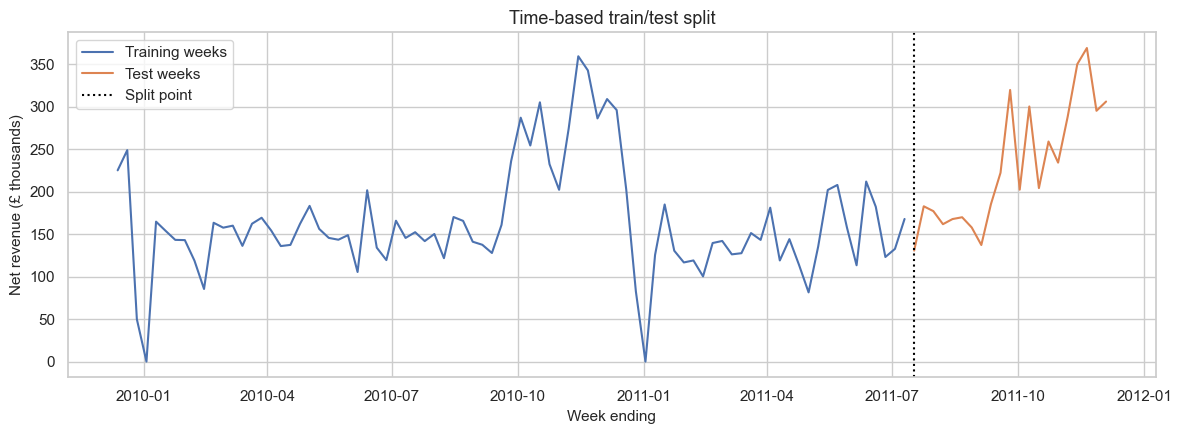

In [7]:
split_position = int(len(weekly_revenue) * 0.8)
train_weeks = weekly_revenue.index[:split_position]
test_weeks = weekly_revenue.index[split_position:]
print(f"Train: {len(train_weeks)} weeks ({train_weeks.min().date()} to {train_weeks.max().date()})")
print(f"Test : {len(test_weeks)} weeks ({test_weeks.min().date()} to {test_weeks.max().date()})")

fig, ax = plt.subplots()
ax.plot(train_weeks, weekly_revenue.loc[train_weeks] / 1e3, color=MAIN_COLOR, label="Training weeks")
ax.plot(test_weeks, weekly_revenue.loc[test_weeks] / 1e3, color=ACCENT_COLOR, label="Test weeks")
ax.axvline(test_weeks.min(), color="black", linestyle=":", label="Split point")
ax.set_title("Time-based train/test split")
ax.set_xlabel("Week ending")
ax.set_ylabel("Net revenue (£ thousands)")
ax.legend()
save_fig("train_test_split")
plt.show()

## Step 5 — Train and compare models

One function trains every candidate on a set of training weeks and predicts a set of later weeks. Using the same
function for the final test **and** for the cross-validation folds below guarantees identical treatment.

Tree hyper-parameters are kept modest and were not tuned on the test weeks.

**Transparency note:** the combination candidate was added after a first comparison showed that seasonal naive and
daily XGBoost were close and made different errors. Averaging forecasts is a standard technique, and the backtest
below checks it on periods the test set never touched.

In [8]:
WEEKLY_MODELS = {
    "Linear Regression (weekly)": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest (weekly)": RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=RANDOM_STATE),
    "XGBoost (weekly)": XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE),
}
DAILY_MODELS = {
    "Random Forest (daily→weekly)": RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=RANDOM_STATE),
    "XGBoost (daily→weekly)": XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE),
}

COMBINATION = "Combination (seasonal naive + daily XGBoost)"

def fit_and_forecast(fit_weeks, forecast_weeks):
    """Train every candidate on `fit_weeks` and return (weekly predictions for `forecast_weeks`, fitted models)."""
    predictions, fitted = {}, {}
    weekly_train = weekly_table.loc[fit_weeks].dropna(subset=WEEKLY_FEATURES)
    weekly_target = weekly_table.loc[forecast_weeks]

    predictions["Naive (last week)"] = weekly_target["lag_1"].values
    predictions["Training mean"] = np.full(len(forecast_weeks), weekly_train["revenue"].mean())
    predictions["Seasonal naive (last year)"] = weekly_target["same_week_last_year"].values

    for name, template in WEEKLY_MODELS.items():
        model = clone(template).fit(weekly_train[WEEKLY_FEATURES], weekly_train["revenue"])
        predictions[name], fitted[name] = model.predict(weekly_target[WEEKLY_FEATURES]), model

    daily_train = daily_table[daily_table["week_ending"].isin(fit_weeks)].dropna(subset=DAILY_FEATURES)
    daily_target = daily_table[daily_table["week_ending"].isin(forecast_weeks)]
    for name, template in DAILY_MODELS.items():
        model = clone(template).fit(daily_train[DAILY_FEATURES], daily_train["revenue"])
        daily_prediction = pd.Series(np.clip(model.predict(daily_target[DAILY_FEATURES]), 0, None), index=daily_target.index)
        predictions[name] = daily_prediction.groupby(daily_target["week_ending"]).sum().reindex(forecast_weeks).values
        fitted[name] = model

    # Forecast combination: equal-weight average of last year's value and the daily XGBoost forecast
    predictions[COMBINATION] = (predictions["Seasonal naive (last year)"] + predictions["XGBoost (daily→weekly)"]) / 2
    return predictions, fitted

test_predictions, fitted_models = fit_and_forecast(train_weeks, test_weeks)
y_test = weekly_revenue.loc[test_weeks]

metrics = pd.DataFrame({
    name: {"test_MAE": mean_absolute_error(y_test, p), "test_RMSE": np.sqrt(mean_squared_error(y_test, p)),
           "test_R2": r2_score(y_test, p), "test_MAPE_%": np.mean(np.abs(y_test - p) / y_test) * 100}
    for name, p in test_predictions.items()}).T.sort_values("test_MAE")
metrics.round(3)

,test_MAE,test_RMSE,test_R2,test_MAPE_%
Combination (seasonal naive + daily XGBoost),31966.242,41784.911,0.652,14.439
Seasonal naive (last year),33707.280,44281.193,0.609,15.608
XGBoost (daily→weekly),35195.563,43326.614,0.626,15.305
XGBoost (weekly),37109.066,49511.342,0.512,16.151
Random Forest (daily→weekly),40203.672,50356.298,0.495,17.133
Random Forest (weekly),41557.835,50142.589,0.499,17.546
Linear Regression (weekly),44972.940,55536.624,0.386,19.208
Naive (last week),44981.907,56518.721,0.364,19.521
Training mean,71648.023,96037.339,-0.837,26.198


**Metrics in plain language:** **MAE** — average weekly miss in £. **RMSE** — like MAE but punishes big misses more.
**R²** — share of week-to-week variation explained (1 = perfect, 0 = no better than the test-period average).
**MAPE** — average miss as a percentage of actual revenue.

### Robustness check — rolling-origin backtest inside the training period

A single 21-week test period could be lucky. We repeat the whole procedure on three earlier 10-week windows inside the
training period (each trained only on weeks before it). The windows start at week 53 so that the seasonal-naive
baseline has a full year of history.

In [9]:
backtest_rows = []
for start in range(52, split_position - 9, 10):
    fold_fit, fold_forecast = weekly_revenue.index[:start], weekly_revenue.index[start:start + 10]
    fold_predictions, _ = fit_and_forecast(fold_fit, fold_forecast)
    for name, p in fold_predictions.items():
        backtest_rows.append({"fold": f"{fold_forecast.min().date()} to {fold_forecast.max().date()}", "model": name,
                              "MAE": mean_absolute_error(weekly_revenue.loc[fold_forecast], p)})
backtest = pd.DataFrame(backtest_rows).pivot(index="model", columns="fold", values="MAE")
backtest["mean_backtest_MAE"] = backtest.mean(axis=1)
metrics["backtest_MAE"] = backtest["mean_backtest_MAE"]
backtest.sort_values("mean_backtest_MAE").round(0)

fold,2010-12-12 to 2011-02-13,2011-02-20 to 2011-04-24,2011-05-01 to 2011-07-03,mean_backtest_MAE
model,,,,
Seasonal naive (last year),27484.0,21779.0,35542.0,28268.0
Combination (seasonal naive + daily XGBoost),46727.0,20773.0,32829.0,33443.0
Linear Regression (weekly),53463.0,20998.0,36495.0,36985.0
Naive (last week),58334.0,24609.0,45045.0,42663.0
Random Forest (daily→weekly),75213.0,16376.0,40419.0,44003.0
Random Forest (weekly),77611.0,21233.0,33912.0,44252.0
XGBoost (weekly),73760.0,25635.0,34237.0,44544.0
XGBoost (daily→weekly),75971.0,19767.0,39044.0,44927.0
Training mean,72148.0,34154.0,39278.0,48527.0


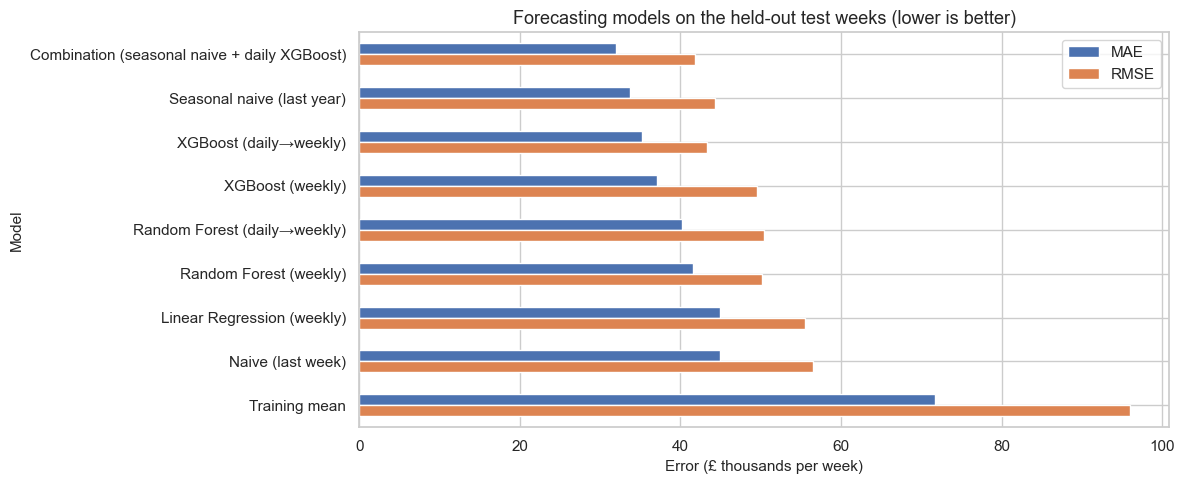

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
metrics[["test_MAE", "test_RMSE"]].div(1e3).plot.barh(ax=ax, color=[MAIN_COLOR, ACCENT_COLOR])
ax.invert_yaxis()
ax.set_title("Forecasting models on the held-out test weeks (lower is better)")
ax.set_xlabel("Error (£ thousands per week)")
ax.set_ylabel("Model")
ax.legend(["MAE", "RMSE"])
save_fig("model_comparison")
plt.show()

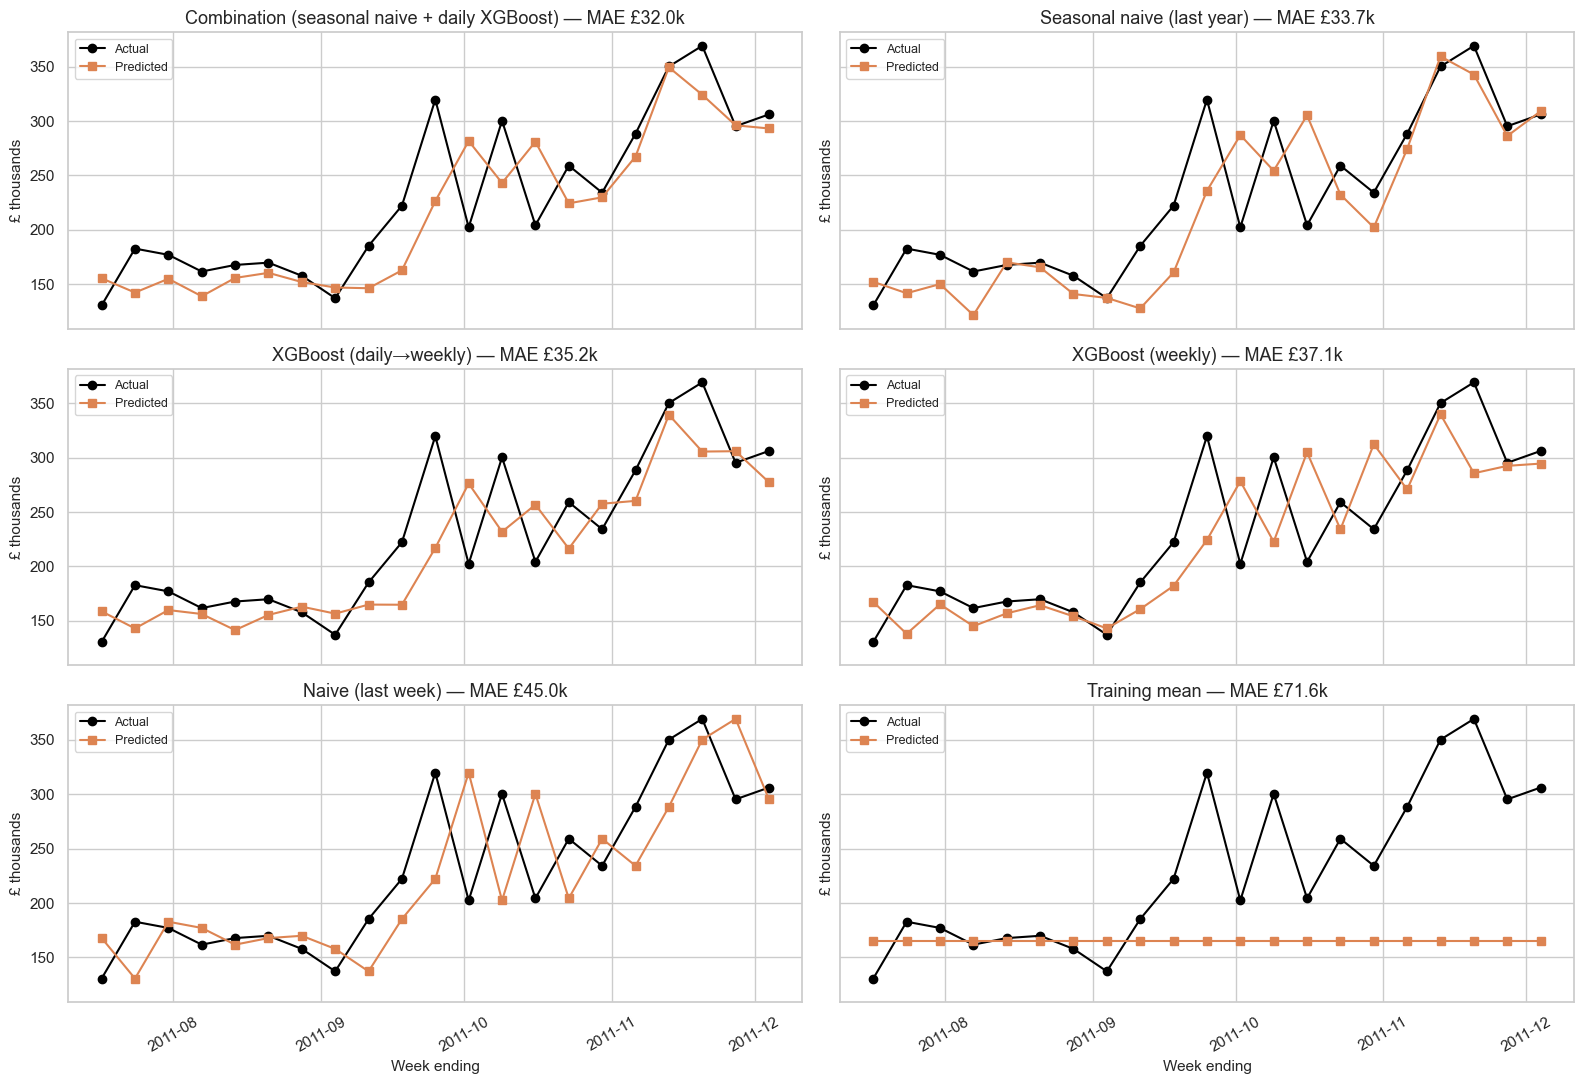

In [11]:
plot_models = [COMBINATION, "Seasonal naive (last year)", "XGBoost (daily→weekly)", "XGBoost (weekly)", "Naive (last week)", "Training mean"]
fig, axes = plt.subplots(3, 2, figsize=(16, 11), sharex=True, sharey=True)
for ax, name in zip(axes.flat, plot_models):
    ax.plot(test_weeks, y_test / 1e3, marker="o", color="black", label="Actual")
    ax.plot(test_weeks, test_predictions[name] / 1e3, marker="s", color=ACCENT_COLOR, label="Predicted")
    ax.set_title(f"{name} — MAE £{metrics.loc[name, 'test_MAE'] / 1e3:,.1f}k")
    ax.set_ylabel("£ thousands")
    ax.legend(loc="upper left", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("Week ending")
    ax.tick_params(axis="x", rotation=30)
save_fig("actual_vs_predicted_all")
plt.show()

**Interpretation:**
- Unlike version 1 of this project, the models now clearly learn something: every forecast that uses the past beats the
  **training mean** (MAE ≈ £72k) by a wide margin, because the training mean cannot follow the autumn rise.
- **Seasonal naive** (same week last year) is a very strong baseline (MAE ≈ £33.7k): the 2011 autumn closely repeats 2010.
- **Daily XGBoost** is the best single ML model (MAE ≈ £35.2k) and has a better RMSE and R² than seasonal naive, meaning
  it makes fewer *large* misses. Modelling days instead of weeks helped both tree models (XGBoost £37.1k → £35.2k,
  Random Forest £41.6k → £40.2k).
- The **combination** of the two has the lowest error on every test metric: MAE ≈ £32.0k (MAPE ≈ 14 %), R² ≈ 0.65.
  The two components make different mistakes — seasonal naive copies last year's week-to-week noise, while XGBoost
  reacts to the most recent weeks — so averaging cancels part of both.
- **Backtest:** in the first window (Dec 2010 – Feb 2011) every ML model fails badly (MAE ≈ £75k) because it had been
  trained on less than a year of data and had never seen a complete Christmas closure; seasonal naive is best there.
  In the later windows, once a full year of history is available, the combination beats seasonal naive
  (e.g. May–Jul 2011: £32.8k vs £35.5k). Averaged over all three windows, seasonal naive still has the lowest backtest error,
  which is an honest reminder that ML needs at least one full seasonal cycle of history.

## Step 6 — Select the model and inspect its errors

In [12]:
selected_model_name = metrics["test_MAE"].idxmin()
seasonal_mae = metrics.loc["Seasonal naive (last year)", "test_MAE"]
selected_mae = metrics.loc[selected_model_name, "test_MAE"]
print("Selected model        :", selected_model_name)
print(f"Test MAE / RMSE       : £{selected_mae:,.0f} / £{metrics.loc[selected_model_name, 'test_RMSE']:,.0f}")
print(f"Improvement vs seasonal naive: {1 - selected_mae / seasonal_mae:.1%}  (MAE £{seasonal_mae:,.0f})")
print(f"Improvement vs training mean : {1 - selected_mae / metrics.loc['Training mean', 'test_MAE']:.1%}")
print(f"Best on backtest      : {metrics['backtest_MAE'].idxmin()}")

# Stability check: does the daily XGBoost result depend on the random seed?
daily_train = daily_table[daily_table["week_ending"].isin(train_weeks)].dropna(subset=DAILY_FEATURES)
daily_target = daily_table[daily_table["week_ending"].isin(test_weeks)]
seed_maes = []
for seed in range(5):
    template = clone(DAILY_MODELS["XGBoost (daily→weekly)"]).set_params(random_state=seed, subsample=0.9)
    p = np.clip(template.fit(daily_train[DAILY_FEATURES], daily_train["revenue"]).predict(daily_target[DAILY_FEATURES]), 0, None)
    seed_maes.append(mean_absolute_error(y_test, pd.Series(p, index=daily_target.index).groupby(daily_target["week_ending"]).sum()))
print(f"Daily XGBoost with 5 random seeds (subsample=0.9): test MAE £{np.mean(seed_maes):,.0f} ± £{np.std(seed_maes):,.0f}")

Selected model        : Combination (seasonal naive + daily XGBoost)
Test MAE / RMSE       : £31,966 / £41,785
Improvement vs seasonal naive: 5.2%  (MAE £33,707)
Improvement vs training mean : 55.4%
Best on backtest      : Seasonal naive (last year)


Daily XGBoost with 5 random seeds (subsample=0.9): test MAE £34,552 ± £1,155


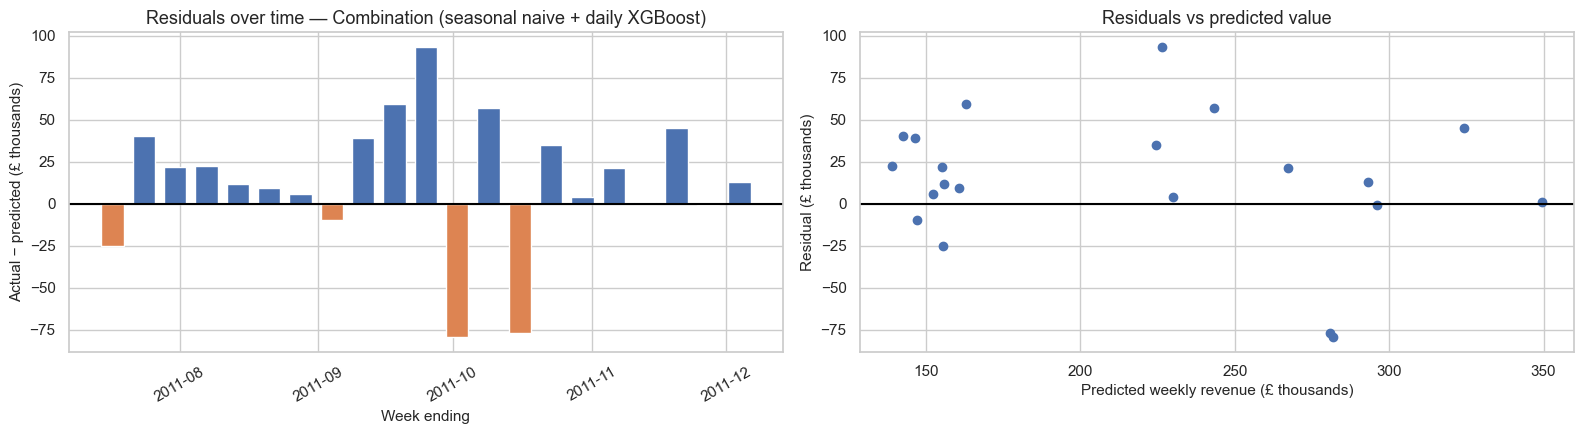

Mean residual (bias): £13,716 | weeks under-predicted: 16 of 21


In [13]:
selected_predictions = test_predictions[selected_model_name]
residuals = y_test - selected_predictions
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].bar(test_weeks, residuals / 1e3, width=5, color=np.where(residuals >= 0, MAIN_COLOR, ACCENT_COLOR))
axes[0].axhline(0, color="black")
axes[0].set_title(f"Residuals over time — {selected_model_name}")
axes[0].set_xlabel("Week ending")
axes[0].set_ylabel("Actual − predicted (£ thousands)")
axes[0].tick_params(axis="x", rotation=30)
axes[1].scatter(selected_predictions / 1e3, residuals / 1e3, color=MAIN_COLOR)
axes[1].axhline(0, color="black")
axes[1].set_title("Residuals vs predicted value")
axes[1].set_xlabel("Predicted weekly revenue (£ thousands)")
axes[1].set_ylabel("Residual (£ thousands)")
save_fig("selected_model_residuals")
plt.show()
print(f"Mean residual (bias): £{residuals.mean():,.0f} | weeks under-predicted: {(residuals > 0).sum()} of {len(residuals)}")

**Interpretation:** the forecast **under-predicts in 16 of 21 test weeks** (average bias ≈ +£13.7k). The reason is
visible in the chart: 2011's autumn was stronger than 2010's, and half of the combination is last year's value, so it lags behind growth.
The largest misses are single unusual weeks in late September and October (e.g. one week ≈ £93k higher than predicted, followed by two
weeks ≈ £78k lower), which look like large wholesale orders landing in a particular week — events no calendar-based model can foresee.
A natural improvement would be a growth adjustment (scaling last year's value by this year's year-over-year trend).

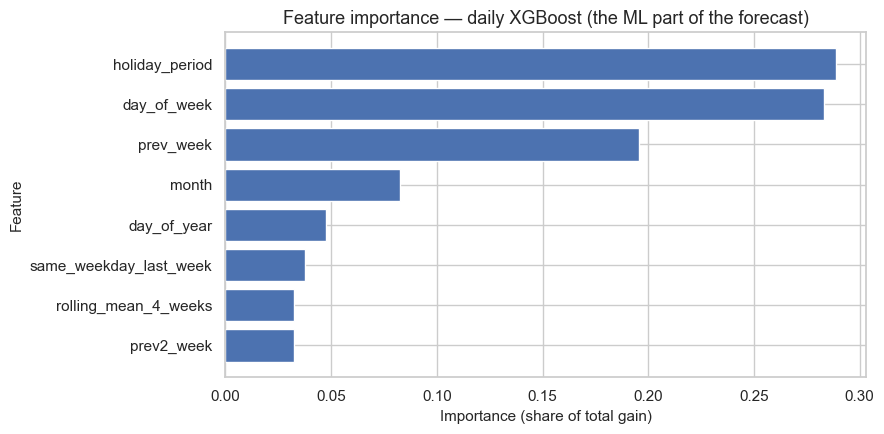

holiday_period            0.289
day_of_week               0.283
prev_week                 0.196
month                     0.082
day_of_year               0.048
same_weekday_last_week    0.038
rolling_mean_4_weeks      0.033
prev2_week                0.032


In [14]:
xgb_daily = fitted_models["XGBoost (daily→weekly)"]
if True:
    importance = pd.Series(xgb_daily.feature_importances_, index=DAILY_FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh(importance.index, importance.values, color=MAIN_COLOR)
    ax.set_title("Feature importance — daily XGBoost (the ML part of the forecast)")
    ax.set_xlabel("Importance (share of total gain)")
    ax.set_ylabel("Feature")
    save_fig("feature_importance")
    plt.show()
    print(importance.sort_values(ascending=False).round(3).to_string())

**Interpretation:** the daily XGBoost relies mainly on **holiday_period** (Christmas closure), **day_of_week**
(Saturday = no trading) and **prev_week** (the most recent weekly level), followed by month. In other words it has learned
the calendar and the current level of demand — the patterns we saw in Steps 1–2.

## Step 7 — Save results

In [15]:
metrics.round(3).to_csv(TABLE_DIR / "01_forecast_metrics.csv", index_label="model")
backtest.round(1).to_csv(TABLE_DIR / "01_forecast_backtest.csv", index_label="model")

prediction_table = pd.DataFrame({"week_ending": test_weeks.date, "actual_revenue": y_test.values})
for name, p in test_predictions.items():
    prediction_table[f"pred_{name}"] = np.round(p, 2)
prediction_table["selected_model"] = selected_model_name
prediction_table["selected_prediction"] = np.round(selected_predictions, 2)
prediction_table.to_csv(PRED_DIR / "01_forecast_test_predictions.csv", index=False)

joblib.dump({"selected_model_name": selected_model_name,
             "xgb_daily_model": xgb_daily, "daily_feature_columns": DAILY_FEATURES,
             "combination_rule": "0.5 * same week last year + 0.5 * daily XGBoost weekly total",
             "train_weeks": (str(train_weeks.min().date()), str(train_weeks.max().date()))},
            MODEL_DIR / "01_forecast_selected.joblib")
print("Saved metrics, backtest, test predictions and the selected model.")

Saved metrics, backtest, test predictions and the selected model.


## Conclusion and limitations

**Selected approach:** the **combination of seasonal naive and daily XGBoost** — test MAE ≈ £32.0k per week
(≈ 14 % of actual revenue), **5.2 % better than seasonal naive** and **55 % better than the training mean**. The best
single ML model is daily XGBoost (MAE ≈ £35.2k; stable across random seeds at ≈ £34.6k ± £1.2k).

**Why this result is more trustworthy than version 1:** weekly revenue in Online Retail II has real, repeating structure
(Ljung–Box p ≈ 0, clear November peak in both years), and the backtest shows where ML helps (after a full year of history)
and where it does not (before it).

**Limitations:**
- Only two years of data → only **one** previous season to learn from; the test set is 21 weeks.
- The combination was added after a first comparison (disclosed above); its advantage over seasonal naive is modest and
  does not hold in the earliest backtest window.
- Forecasts systematically lag year-over-year growth; one-off wholesale orders cause large single-week misses.
- No external drivers (promotions, marketing, stock levels) are available.

**What would improve it:** more years of history, a year-over-year growth adjustment, forecasting UK and wholesale
customers separately, and promotional calendars.